<a href="https://colab.research.google.com/github/kaixing189/MSSP607/blob/main/Week8_Participation_Activity_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MSSP607 Week 8 Participation Activity


## Part 1. Clone the MSSP607 GitHub Repository



```text
MSSP607/data/InternetSales.csv
```

In [1]:
from pathlib import Path
import os
import subprocess

REPO_URL = "https://github.com/kaixing189/MSSP607.git"
REPO_DIR = Path("/content/MSSP607")

if REPO_DIR.exists():
    subprocess.run(
        ["git", "-C", str(REPO_DIR), "pull"],
        check=True
    )
    print("Repository already exists. Latest changes were pulled.")
else:
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_DIR)],
        check=True
    )
    print("Repository cloned successfully.")

os.chdir(REPO_DIR)
print("Current working directory:", os.getcwd())

Repository cloned successfully.
Current working directory: /content/MSSP607


## Part 2. Load and Inspect the Internet Sales Data



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_PATH = REPO_DIR / "data" / "InternetSales.csv"

sales = pd.read_csv(
    DATA_PATH,
    encoding="cp1252",
    low_memory=False
)

print("Shape:", sales.shape)
sales.head()

Shape: (60398, 60)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


The data contain **60,398 rows and 60 columns**. The main variables used in this activity are:

- `OrderDate`: sales order date
- `SalesAmount`: sales amount
- `EnglishProductName`: product name

## Part 3. Prepare the Date Variable



In [3]:
sales["OrderDate"] = pd.to_datetime(sales["OrderDate"])
sales["Year"] = sales["OrderDate"].dt.year

print("First date:", sales["OrderDate"].min())
print("Last date:", sales["OrderDate"].max())
print("Years:", sorted(sales["Year"].unique()))

First date: 2010-12-29 00:00:00
Last date: 2014-01-28 00:00:00
Years: [np.int32(2010), np.int32(2011), np.int32(2012), np.int32(2013), np.int32(2014)]


## Part 4. Calculate Yearly Sales



In [4]:
complete_sales = sales[sales["Year"].between(2011, 2013)].copy()

yearly_sales = (
    complete_sales
    .groupby("Year", as_index=False)["SalesAmount"]
    .sum()
    .sort_values("Year")
)

yearly_sales

,Year,SalesAmount
0,2011,7.075526e+06
1,2012,5.842485e+06
2,2013,1.635155e+07


The complete-year sales totals are:

| Year | Total Sales |
|---|---:|
| 2011 | $7,075,525.93 |
| 2012 | $5,842,485.20 |
| 2013 | $16,351,550.34 |

## Part 5. Plot the Historical Sales Trend Line



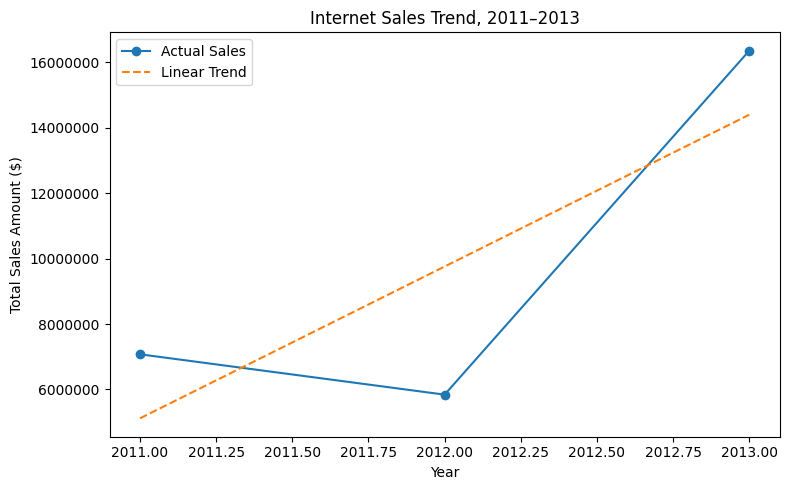

In [5]:
x = yearly_sales["Year"].to_numpy()
y = yearly_sales["SalesAmount"].to_numpy()

slope, intercept = np.polyfit(x, y, 1)
yearly_sales["TrendSales"] = slope * yearly_sales["Year"] + intercept

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    yearly_sales["Year"],
    yearly_sales["SalesAmount"],
    marker="o",
    label="Actual Sales"
)

ax.plot(
    yearly_sales["Year"],
    yearly_sales["TrendSales"],
    linestyle="--",
    label="Linear Trend"
)

ax.set_title("Internet Sales Trend, 2011–2013")
ax.set_xlabel("Year")
ax.set_ylabel("Total Sales Amount ($)")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()

fig.tight_layout()
plt.show()

## Part 6. Forecast Internet Sales for the Next Five Years



In [6]:
forecast_years = np.arange(2014, 2019)
forecast_sales = slope * forecast_years + intercept

forecast = pd.DataFrame({
    "Year": forecast_years,
    "ForecastSales": forecast_sales
})

forecast["ForecastSales"] = forecast["ForecastSales"].round(2)
forecast

,Year,ForecastSales
0,2014,19032544.90
1,2015,23670557.10
2,2016,28308569.31
3,2017,32946581.52
4,2018,37584593.72


### Five-Year Forecast

| Year | Forecast Sales |
|---|---:|
| 2014 | $19,032,544.90 |
| 2015 | $23,670,557.10 |
| 2016 | $28,308,569.31 |
| 2017 | $32,946,581.52 |
| 2018 | $37,584,593.72 |

These estimates are produced by a simple linear trend model. They are appropriate for this classroom demonstration but should not be treated as real forecasts.

## Part 7. Plot Historical Sales and the Five-Year Forecast

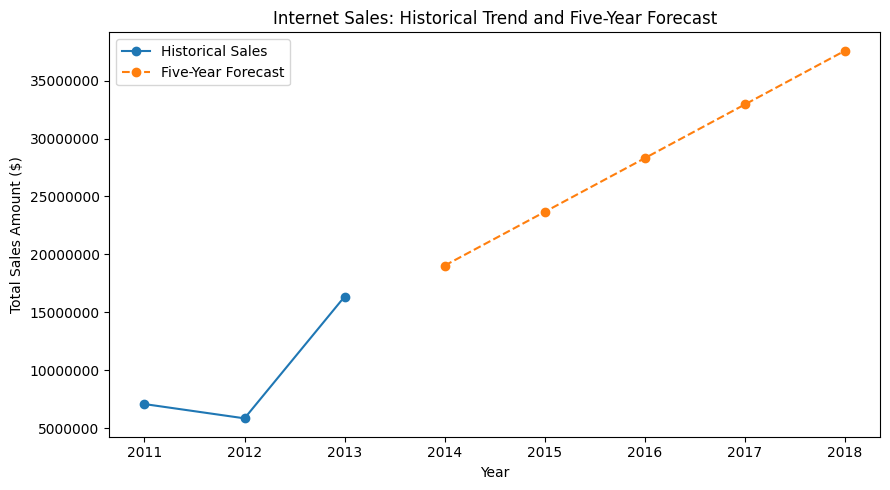

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    yearly_sales["Year"],
    yearly_sales["SalesAmount"],
    marker="o",
    label="Historical Sales"
)

ax.plot(
    forecast["Year"],
    forecast["ForecastSales"],
    marker="o",
    linestyle="--",
    label="Five-Year Forecast"
)

ax.set_title("Internet Sales: Historical Trend and Five-Year Forecast")
ax.set_xlabel("Year")
ax.set_ylabel("Total Sales Amount ($)")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()

fig.tight_layout()
plt.show()

## Part 8. Product Summary Statistics


In [8]:
product_summary = (
    sales.groupby("EnglishProductName")["SalesAmount"]
    .agg(["count", "sum", "mean", "median", "std"])
    .rename(columns={
        "count": "Transactions",
        "sum": "TotalSales",
        "mean": "MeanSale",
        "median": "MedianSale",
        "std": "StdDev"
    })
    .sort_values("TotalSales", ascending=False)
)

product_summary.head(10)

,Transactions,TotalSales,MeanSale,MedianSale,StdDev
EnglishProductName,,,,,
"Mountain-200 Black, 46",620,1.373470e+06,2215.273465,2294.99,115.188180
"Mountain-200 Black, 42",614,1.363142e+06,2220.101129,2294.99,113.256820
"Mountain-200 Silver, 38",596,1.339463e+06,2247.420789,2319.99,113.109387
"Mountain-200 Silver, 46",580,1.301100e+06,2243.276032,2319.99,114.919793
"Mountain-200 Black, 38",582,1.294866e+06,2224.855913,2294.99,111.120758
"Mountain-200 Silver, 42",560,1.257435e+06,2245.418880,2319.99,114.011108
"Road-150 Red, 48",337,1.205877e+06,3578.270000,3578.27,0.000000
"Road-150 Red, 62",336,1.202299e+06,3578.270000,3578.27,0.000000
"Road-150 Red, 52",302,1.080638e+06,3578.270000,3578.27,0.000000


### Product with the Highest Historical Sales

The product with the highest historical total sales is:

**Mountain-200 Black, 46**

Its summary statistics are:

- **Total Sales:** $1,373,469.55
- **Transactions:** 620
- **Mean Sale:** $2,215.27
- **Median Sale:** $2,294.99

Based on the historical summary statistics, **Mountain-200 Black, 46** is the strongest candidate to generate the most sales if the historical sales pattern continues.

This is a conclusion based on historical summary statistics, not a separate product-level forecast.

## Part 9. Final Answers

### Question 2: Five-Year Internet Sales Forecast
The linear trend model forecasts increasing Internet Sales from 2014 through 2018. The projected values are shown in the table above.

### Question 3: Which Product Will Generate the Most Sales?
Based on historical total `SalesAmount`, **Mountain-200 Black, 46** ranks first.

### Question 4: Sales Trend
The trend chart shows an overall upward trend across the complete calendar years, although the historical totals are not perfectly linear.

Because the AdventureWorks data are fictitious and the forecast uses only three complete annual observations, these results are for demonstration only.